# KRM (Karen Rumbi Model): Women's Reproductive Health Risk Assessment, Zimbabwe
## Data analytics and model development notebook

**Study:** An Explainable Ensemble Machine Learning-Based Predictive Decision Support Framework for Women's Reproductive Health Risk Assessment in Zimbabwe Using Dietary and Environmental Factors.



### How to run it on your computer
1. Put this notebook and `krm_dataset.csv` in the same folder.
2. Create a clean environment and install the pinned versions: `pip install -r requirements.txt` (Python 3.12 is recommended).
3. Open the notebook in Jupyter and choose **Kernel > Restart & Run All**.
4. The saved model appears in a new `models/` folder.

## 1. Setup and data import

In [1]:
import json, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn, xgboost, shap

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve, auc)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

SEED = 42
N_SAMPLE = 4300
CLASS_NAMES = ["Low", "Moderate", "High"]
PALETTE = {"Low": "#4C9F70", "Moderate": "#E3A72F", "High": "#C8423B"}

print("Python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)
print("shap        :", shap.__version__)

# The saved model files only load safely under the library versions that wrote them.
PINNED = {"scikit-learn": "1.9.1", "xgboost": "3.4.1", "shap": "0.53.0"}
found = {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__}
for k, v in PINNED.items():
    if found[k] != v:
        print(f"NOTE: {k} is {found[k]}, the thesis results used {v}. Small numeric differences are possible.")

Python      : 3.12.3
scikit-learn: 1.9.1
xgboost     : 3.4.1
shap        : 0.53.0


C:\Users\tapiwanashec\Documents\taps\Karen\krm_notebook\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# The 4,300-record dataset must sit in the same folder as this notebook.
DATA_PATH = Path("krm_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Put krm_dataset.csv in the same folder as this notebook.")

# keep_default_na=False matters: the category value "None" (no pesticide exposure,
# no alcohol use) would otherwise be silently read as a missing value by pandas.
df = pd.read_csv(DATA_PATH, keep_default_na=False)
print(f"Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns  <- {DATA_PATH}")
df.head()

Dataset: 4,300 rows x 21 columns  <- krm_dataset.csv


,respondent_id,age,province,residence,processed_food_frequency_1_5,fruit_vegetable_frequency_1_5,legume_frequency_1_5,physical_activity,sleep_hours,stress_level,...,pesticide_exposure,air_pollution_exposure,occupational_chemical_exposure,smoking,alcohol_use,irregular_menstrual_cycle,severe_menstrual_pain,family_reproductive_history,previous_reproductive_condition,reproductive_health_risk
0,ZW0002,42,Mashonaland East,Urban,2,4,3,Moderate,6.1,High,...,None,Moderate,No,No,Occasional,Yes,No,No,Yes,High
1,ZW0005,31,Harare,Rural,3,2,3,Moderate,7.1,High,...,Moderate,Low,No,No,None,No,No,No,No,Low
2,ZW0006,45,Harare,Urban,2,3,4,Moderate,9.2,Moderate,...,None,High,No,No,None,No,No,No,No,Low
3,ZW0008,40,Mashonaland East,Rural,3,3,3,Low,7.4,Moderate,...,Low,Moderate,No,No,None,No,No,No,No,Low
4,ZW0011,34,Mashonaland West,Urban,2,3,4,Moderate,5.7,Low,...,None,Low,No,No,None,No,No,No,No,Low


## 2. Data quality and metadata

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": (df.isna() | (df.astype(str).apply(lambda s: s.str.strip()) == "")).sum(),
    "unique": df.nunique(),
})
print("Duplicate respondent IDs:", df["respondent_id"].duplicated().sum())
print("Total missing cells     :", int(quality["missing"].sum()))
quality

Duplicate respondent IDs: 0
Total missing cells     : 0


,dtype,missing,unique
respondent_id,str,0,4300
age,int64,0,32
province,str,0,10
residence,str,0,2
processed_food_frequency_1_5,int64,0,5
fruit_vegetable_frequency_1_5,int64,0,5
legume_frequency_1_5,int64,0,5
physical_activity,str,0,3
sleep_hours,float64,0,77
stress_level,str,0,3


In [4]:
num_cols = ["age", "processed_food_frequency_1_5", "fruit_vegetable_frequency_1_5",
            "legume_frequency_1_5", "sleep_hours", "bmi"]
df[num_cols].describe().round(2)

,age,processed_food_frequency_1_5,fruit_vegetable_frequency_1_5,legume_frequency_1_5,sleep_hours,bmi
count,4300.00,4300.00,4300.00,4300.00,4300.00,4300.00
mean,33.26,3.01,3.00,2.98,6.65,24.53
std,9.18,1.07,1.08,1.07,1.30,5.03
min,18.00,1.00,1.00,1.00,3.00,15.00
25%,25.00,2.00,2.00,2.00,5.70,21.00
50%,33.00,3.00,3.00,3.00,6.60,24.40
75%,41.00,4.00,4.00,4.00,7.50,28.00
max,49.00,5.00,5.00,5.00,11.00,45.00


In [5]:
cat_cols = ["province", "residence", "physical_activity", "stress_level", "pesticide_exposure",
            "air_pollution_exposure", "occupational_chemical_exposure", "smoking", "alcohol_use",
            "irregular_menstrual_cycle", "severe_menstrual_pain", "family_reproductive_history",
            "previous_reproductive_condition"]
for c in cat_cols:
    vc = df[c].value_counts()
    print(f"{c:35s}", " | ".join(f"{k}: {v}" for k, v in vc.items()))

province                            Harare: 686 | Midlands: 538 | Masvingo: 483 | Manicaland: 466 | Mashonaland West: 427 | Bulawayo: 406 | Mashonaland East: 381 | Mashonaland Central: 334 | Matabeleland South: 295 | Matabeleland North: 284
residence                           Rural: 2658 | Urban: 1642
physical_activity                   Moderate: 1832 | Low: 1756 | High: 712
stress_level                        Moderate: 1830 | Low: 1478 | High: 992
pesticide_exposure                  None: 2532 | Low: 1029 | Moderate: 492 | High: 247
air_pollution_exposure              Low: 1798 | Moderate: 1676 | High: 826
occupational_chemical_exposure      No: 3362 | Yes: 938
smoking                             No: 4030 | Yes: 270
alcohol_use                         None: 1969 | Occasional: 1379 | Regular: 685 | Heavy: 267
irregular_menstrual_cycle           No: 3520 | Yes: 780
severe_menstrual_pain               No: 3488 | Yes: 812
family_reproductive_history         No: 3629 | Yes: 671
previous_re

**Insight:** no missing values, no duplicate IDs, and every categorical column holds only its expected levels, so the sample is clean enough to model without imputation.

## 3. Exploratory data analysis

### 3.1 Target distribution

                          count  percent
reproductive_health_risk                
Low                        2365     55.0
Moderate                   1290     30.0
High                        645     15.0


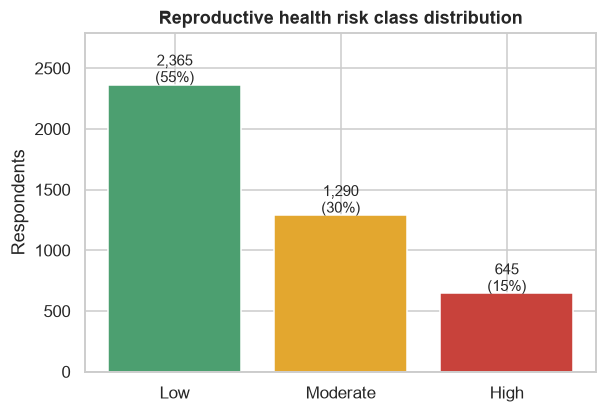

In [6]:
tgt = df["reproductive_health_risk"].value_counts().reindex(CLASS_NAMES)
print(pd.DataFrame({"count": tgt, "percent": (tgt / tgt.sum() * 100).round(1)}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(tgt.index, tgt.values, color=[PALETTE[c] for c in tgt.index])
for b, v in zip(bars, tgt.values):
    ax.text(b.get_x() + b.get_width()/2, v + 20, f"{v:,}\n({v/tgt.sum():.0%})", ha="center", fontsize=10)
ax.set_title("Reproductive health risk class distribution"); ax.set_ylabel("Respondents")
ax.set_ylim(0, tgt.max()*1.18); plt.show()

**Insight:** the classes are imbalanced (about 55% Low, 30% Moderate, 15% High). Accuracy alone would flatter a model that favours Low, so this notebook uses **stratified** splits and **macro-averaged** metrics and watches High-risk recall closely.

### 3.2 Who is in the sample: demographics

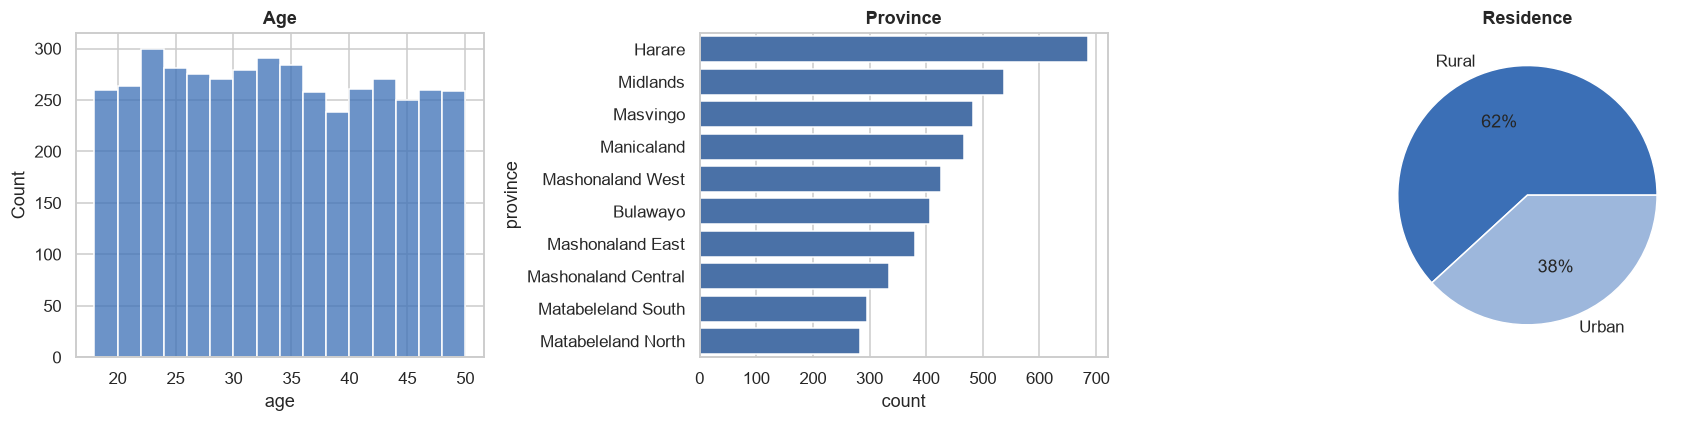

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["age"], bins=range(18, 51, 2), color="#3B6FB6", ax=axes[0]); axes[0].set_title("Age")
order = df["province"].value_counts().index
sns.countplot(y="province", data=df, order=order, color="#3B6FB6", ax=axes[1]); axes[1].set_title("Province")
df["residence"].value_counts().plot.pie(autopct="%1.0f%%", colors=["#3B6FB6", "#9DB7DC"], ax=axes[2], ylabel="")
axes[2].set_title("Residence"); plt.tight_layout(); plt.show()

### 3.3 Numeric features by risk level

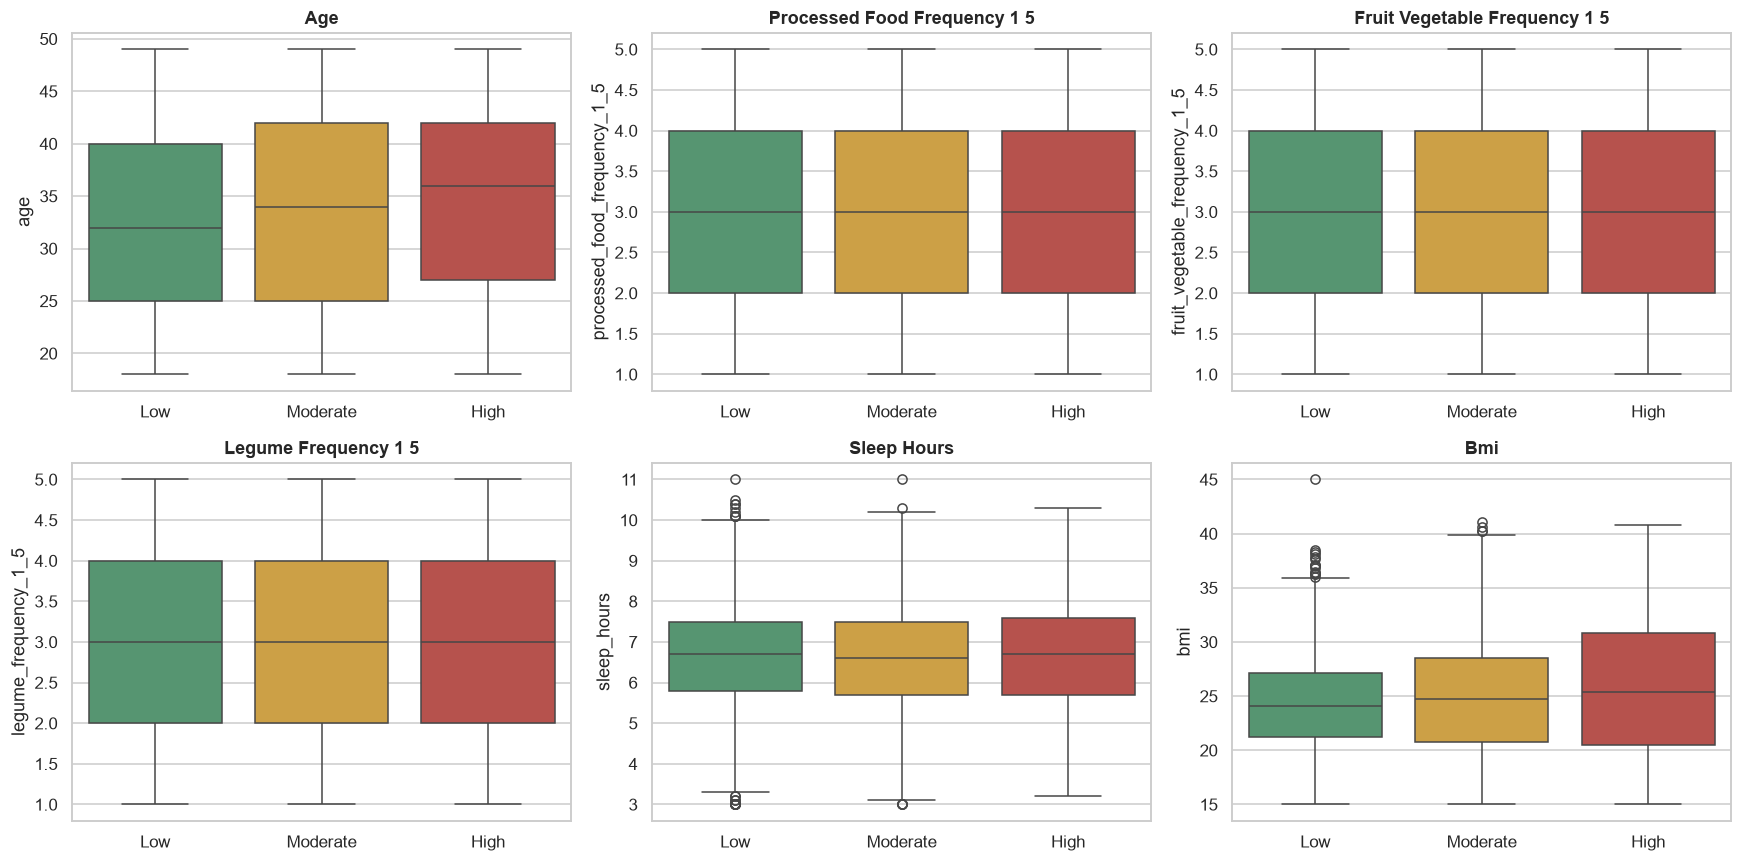

                            age  processed_food_frequency_1_5  \
reproductive_health_risk                                        
Low                       32.51                          2.99   
Moderate                  33.76                          3.02   
High                      35.02                          3.03   

                          fruit_vegetable_frequency_1_5  legume_frequency_1_5  \
reproductive_health_risk                                                        
Low                                                2.99                  2.98   
Moderate                                           2.98                  3.00   
High                                               3.06                  2.97   

                          sleep_hours    bmi  
reproductive_health_risk                      
Low                              6.67  24.14  
Moderate                         6.60  24.77  
High                             6.67  25.51  


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="reproductive_health_risk", y=col, order=CLASS_NAMES, palette=PALETTE, ax=ax)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(df.groupby("reproductive_health_risk")[num_cols].mean().reindex(CLASS_NAMES).round(2))

**Insight:** average age rises from 32.5 (Low) to 35.0 (High) and average BMI from 24.1 to 25.5. Sleep hours and the three dietary frequency scores are almost identical across the classes (for example, mean legume score 2.98 / 3.00 / 2.97), so on their own they are weak separators.

### 3.4 Share of respondents rated High risk, by factor

answer,No,Yes
factor,,
previous_reproductive_condition,10.3,50.7
irregular_menstrual_cycle,8.9,42.7
family_reproductive_history,10.7,38.3
severe_menstrual_pain,11.0,32.4
occupational_chemical_exposure,12.5,23.9
smoking,14.8,18.1


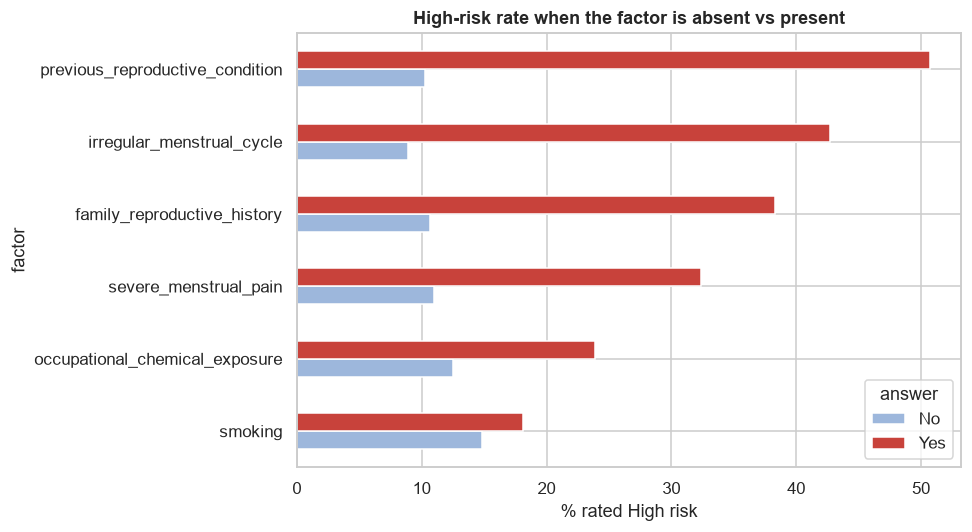

In [9]:
binary_factors = ["previous_reproductive_condition", "irregular_menstrual_cycle",
                  "family_reproductive_history", "severe_menstrual_pain",
                  "occupational_chemical_exposure", "smoking"]
rows = []
for f in binary_factors:
    for lvl in ["No", "Yes"]:
        sub = df[df[f] == lvl]
        rows.append({"factor": f, "answer": lvl, "n": len(sub),
                     "high_risk_%": round((sub["reproductive_health_risk"] == "High").mean()*100, 1)})
hr = pd.DataFrame(rows)
display(hr.pivot(index="factor", columns="answer", values="high_risk_%").sort_values("Yes", ascending=False))

pv = hr.pivot(index="factor", columns="answer", values="high_risk_%").sort_values("Yes")
ax = pv[["No", "Yes"]].plot.barh(figsize=(9, 5), color=["#9DB7DC", "#C8423B"])
ax.set_xlabel("% rated High risk"); ax.set_title("High-risk rate when the factor is absent vs present")
plt.tight_layout(); plt.show()

**Insight:** the clinical-history questions dominate. About 51% of respondents with a previous reproductive condition and 43% of those with an irregular cycle are rated High risk, against roughly 9-10% of those without; family history (38% vs 11%) and severe menstrual pain (32% vs 11%) show the same pattern. These are the strongest signals in the data.

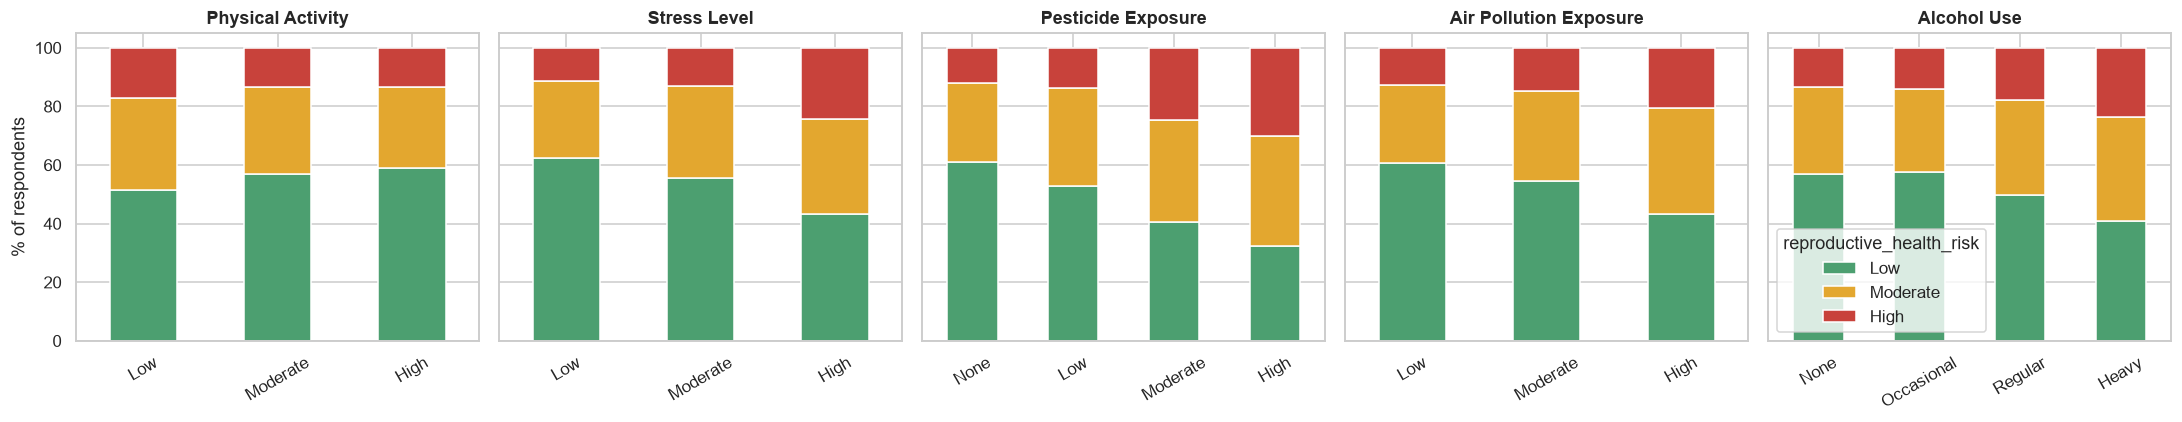

In [10]:
ordinal_factors = ["physical_activity", "stress_level", "pesticide_exposure",
                   "air_pollution_exposure", "alcohol_use"]
level_order = {"physical_activity": ["Low","Moderate","High"], "stress_level": ["Low","Moderate","High"],
               "pesticide_exposure": ["None","Low","Moderate","High"],
               "air_pollution_exposure": ["Low","Moderate","High"],
               "alcohol_use": ["None","Occasional","Regular","Heavy"]}
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, f in zip(axes, ordinal_factors):
    ct = (pd.crosstab(df[f], df["reproductive_health_risk"], normalize="index")
            .reindex(level_order[f])[CLASS_NAMES] * 100)
    ct.plot.bar(stacked=True, color=[PALETTE[c] for c in CLASS_NAMES], ax=ax, legend=(f == ordinal_factors[-1]))
    ax.set_title(f.replace("_", " ").title()); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% of respondents")
plt.tight_layout(); plt.show()

**Insight:** risk climbs steadily with pesticide exposure, air-pollution exposure, stress and alcohol use, which supports including the environmental and lifestyle block in the framework. The effect of each single step is smaller than for the clinical-history questions.

### 3.5 Urban/rural and provincial patterns

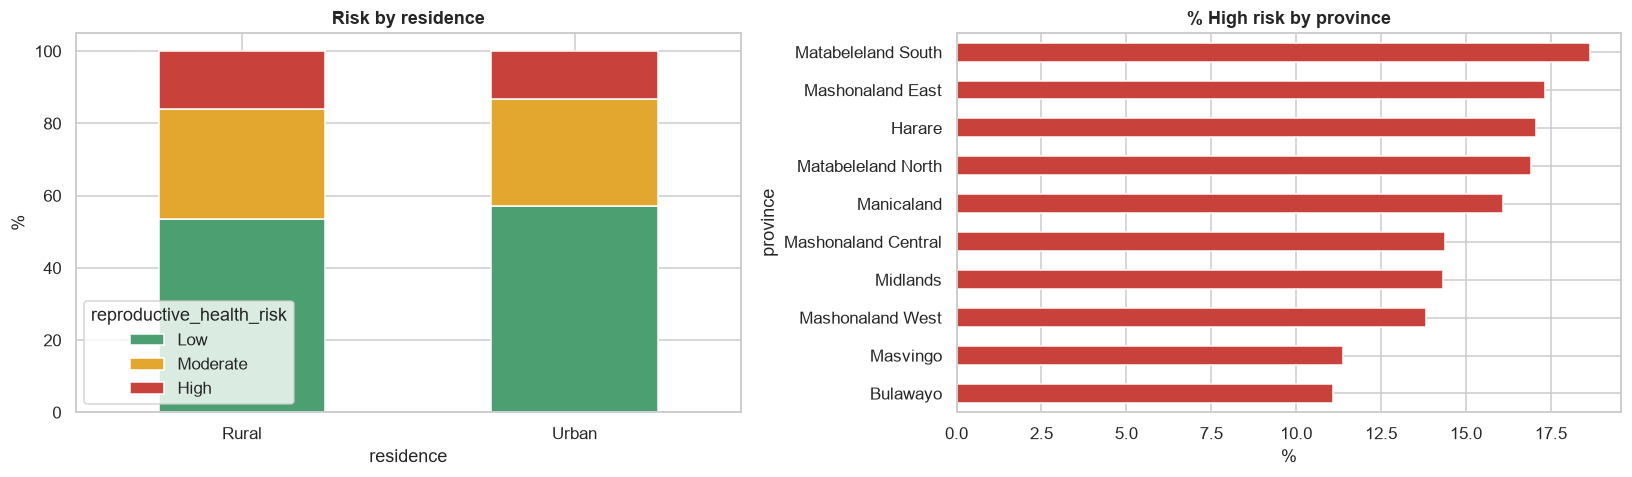

Rural vs urban pesticide exposure (% with any exposure):
residence
Rural    54.7
Urban    19.2
Name: any_pest, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ct = pd.crosstab(df["residence"], df["reproductive_health_risk"], normalize="index")[CLASS_NAMES]*100
ct.plot.bar(stacked=True, color=[PALETTE[c] for c in CLASS_NAMES], ax=axes[0]); axes[0].set_title("Risk by residence")
axes[0].set_ylabel("%"); axes[0].tick_params(axis="x", rotation=0)
prov = (df.assign(high=(df["reproductive_health_risk"]=="High"))
          .groupby("province")["high"].mean().sort_values()*100)
prov.plot.barh(color="#C8423B", ax=axes[1]); axes[1].set_title("% High risk by province"); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()
print("Rural vs urban pesticide exposure (% with any exposure):")
print((df.assign(any_pest=df.pesticide_exposure!='None').groupby('residence')['any_pest'].mean()*100).round(1))

**Insight:** 55% of rural respondents report some pesticide exposure against 19% of urban respondents, so residence influences risk mainly through the environmental variables. Provincial differences are modest and, with roughly 300-700 respondents per province in this sample, should not be over-interpreted.

### 3.6 Correlation of numeric features with risk

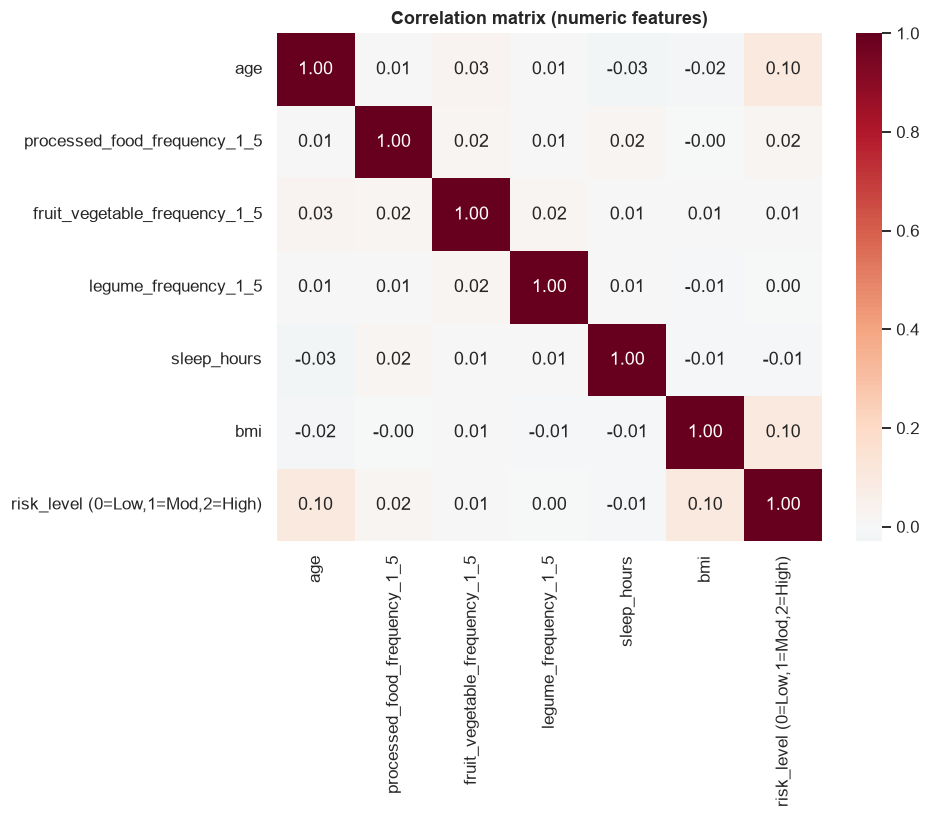

In [12]:
tmp = df[num_cols].copy()
tmp["risk_level (0=Low,1=Mod,2=High)"] = df["reproductive_health_risk"].map({"Low":0,"Moderate":1,"High":2})
plt.figure(figsize=(8, 6))
sns.heatmap(tmp.corr().round(2), annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Correlation matrix (numeric features)"); plt.show()

**Insight:** the strongest correlation between any two numeric predictors is about 0.02, so multicollinearity is not a concern for the linear model. `legume_frequency_1_5` shows almost no relationship with risk, which the SHAP section checks again later.

## 4. Feature engineering

- **Ordinal** columns (activity, stress, pesticide, air pollution, alcohol) become integers that preserve order.
- **Binary** columns (residence, smoking, history flags) become 0/1.
- **BMI category** (Underweight / Normal / Overweight / Obese) is added as dummies so a linear model can represent BMI's U-shaped relationship with risk.
- **Province** is one-hot encoded with Bulawayo as the reference level.
- The encoding dictionaries are saved with the model so the web application encodes new respondents *exactly* as training did.

In [13]:
ORDINAL_MAPS = {
    "physical_activity": {"Low": 0, "Moderate": 1, "High": 2},
    "stress_level": {"Low": 0, "Moderate": 1, "High": 2},
    "pesticide_exposure": {"None": 0, "Low": 1, "Moderate": 2, "High": 3},
    "air_pollution_exposure": {"Low": 0, "Moderate": 1, "High": 2},
    "alcohol_use": {"None": 0, "Occasional": 1, "Regular": 2, "Heavy": 3},
}
BINARY_MAPS = {
    "residence": {"Urban": 0, "Rural": 1},
    "occupational_chemical_exposure": {"No": 0, "Yes": 1},
    "smoking": {"No": 0, "Yes": 1},
    "irregular_menstrual_cycle": {"No": 0, "Yes": 1},
    "severe_menstrual_pain": {"No": 0, "Yes": 1},
    "family_reproductive_history": {"No": 0, "Yes": 1},
    "previous_reproductive_condition": {"No": 0, "Yes": 1},
}
PROVINCES = ["Harare", "Bulawayo", "Manicaland", "Mashonaland Central", "Mashonaland East",
             "Mashonaland West", "Masvingo", "Matabeleland North", "Matabeleland South", "Midlands"]
REFERENCE_PROVINCE = "Bulawayo"
NUMERIC_TO_SCALE = ["age", "processed_food_frequency_1_5", "fruit_vegetable_frequency_1_5",
                    "legume_frequency_1_5", "sleep_hours", "bmi"]

def bmi_category(b):
    return "Underweight" if b < 18.5 else "Normal" if b < 25 else "Overweight" if b < 30 else "Obese"

def engineer(frame):
    out = frame[NUMERIC_TO_SCALE].copy()
    for c, m in ORDINAL_MAPS.items(): out[c] = frame[c].map(m)
    for c, m in BINARY_MAPS.items():  out[c] = frame[c].map(m)
    cat = frame["bmi"].apply(bmi_category)
    for lvl in ["Obese", "Overweight", "Underweight"]:      # Normal is the reference level
        out[f"bmi_cat_{lvl}"] = (cat == lvl).astype(int)
    for p in PROVINCES:
        if p != REFERENCE_PROVINCE:
            out[f"province_{p}"] = (frame["province"] == p).astype(int)
    return out

X = engineer(df)
y = df["reproductive_health_risk"].map({c: i for i, c in enumerate(CLASS_NAMES)}).astype(int)
assert X.isna().sum().sum() == 0
FEATURE_COLS = list(X.columns)
print(f"{df.shape[1]-2} raw predictors  ->  {X.shape[1]} model features")
X.head(3).T

19 raw predictors  ->  30 model features


,0,1,2
age,42.0,31.0,45.0
processed_food_frequency_1_5,2.0,3.0,2.0
fruit_vegetable_frequency_1_5,4.0,2.0,3.0
legume_frequency_1_5,3.0,3.0,4.0
sleep_hours,6.1,7.1,9.2
bmi,23.9,25.4,27.0
physical_activity,1.0,1.0,1.0
stress_level,2.0,2.0,1.0
pesticide_exposure,0.0,2.0,0.0
air_pollution_exposure,1.0,0.0,2.0


## 5. Train/test split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
split = pd.DataFrame({
    "train": y_train.map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES),
    "test":  y_test.map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES)})
split["train_%"] = (split.train/split.train.sum()*100).round(1)
split["test_%"]  = (split.test/split.test.sum()*100).round(1)
print(f"Train: {len(X_train):,}   Test: {len(X_test):,}   Features: {X_train.shape[1]}")
split

Train: 3,440   Test: 860   Features: 30


,train,test,train_%,test_%
reproductive_health_risk,,,,
Low,1892,473,55.0,55.0
Moderate,1032,258,30.0,30.0
High,516,129,15.0,15.0


The test set is set aside here and is not touched again until the final evaluation. All tuning happens through cross-validation on the training set only.

## 6. Base models, tuned with stratified 5-fold cross-validation

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
num_idx = [FEATURE_COLS.index(c) for c in NUMERIC_TO_SCALE]

from sklearn.compose import ColumnTransformer
def make_lr(C=1.0):
    # scaling lives INSIDE the pipeline, so the saved model accepts raw engineered features
    pre = ColumnTransformer([("num", StandardScaler(), num_idx)], remainder="passthrough")
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=3000, random_state=SEED))])

searches = {
    "Logistic Regression": GridSearchCV(make_lr(), {"clf__C": [0.1, 1, 10]},
                                        cv=cv, scoring="f1_macro", n_jobs=-1),
    "Random Forest": GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1),
                                  {"n_estimators": [200, 400], "max_depth": [None, 12],
                                   "min_samples_leaf": [1, 3]},
                                  cv=cv, scoring="f1_macro", n_jobs=-1),
    "XGBoost": GridSearchCV(XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                                          random_state=SEED, n_jobs=1),
                            {"n_estimators": [200, 400], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]},
                            cv=cv, scoring="f1_macro", n_jobs=-1),
}
tuned = {}
rows = []
for name, gs in searches.items():
    gs.fit(X_train.values, y_train.values)
    tuned[name] = gs.best_estimator_
    rows.append({"model": name, "best CV macro-F1": round(gs.best_score_, 4), "best params": gs.best_params_})
    print(f"{name:20s} CV macro-F1 = {gs.best_score_:.4f}   {gs.best_params_}")
pd.DataFrame(rows)

Logistic Regression  CV macro-F1 = 0.6879   {'clf__C': 10}
Random Forest        CV macro-F1 = 0.6429   {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}
XGBoost              CV macro-F1 = 0.6783   {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}


,model,best CV macro-F1,best params
0,Logistic Regression,0.6879,{'clf__C': 10}
1,Random Forest,0.6429,"{'max_depth': None, 'min_samples_leaf': 3, 'n_..."
2,XGBoost,0.6783,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."


## 7. KRM: the stacking ensemble

KRM combines the three tuned base models. Each base model produces **out-of-fold** class probabilities (5-fold), and a Logistic Regression **meta-learner** learns how to weigh those 9 probability columns (3 models x 3 classes). Using out-of-fold predictions stops the meta-learner from simply trusting models that memorised the training data.

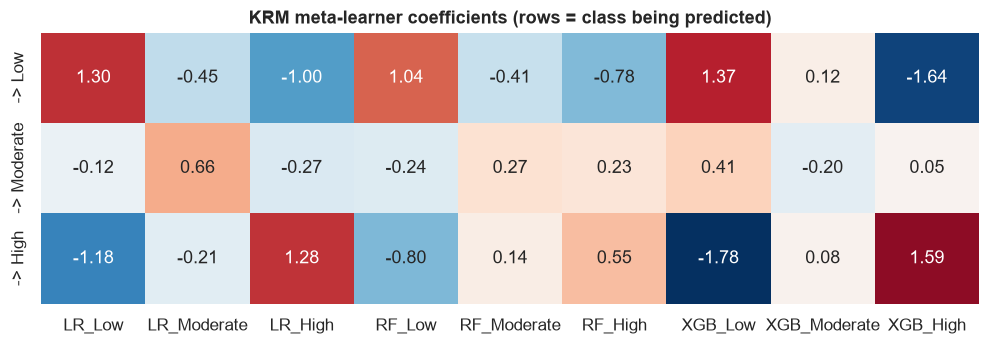

In [16]:
from sklearn.base import clone
krm = StackingClassifier(
    estimators=[("lr", clone(tuned["Logistic Regression"])),
                ("rf", clone(tuned["Random Forest"])),
                ("xgb", clone(tuned["XGBoost"]))],
    final_estimator=LogisticRegression(max_iter=3000, random_state=SEED),
    stack_method="predict_proba", cv=cv, n_jobs=1, passthrough=False)
krm.fit(X_train.values, y_train.values)

# What the meta-learner learned: weight given to each base model's probability for each class
cols = [f"{m}_{c}" for m in ["LR", "RF", "XGB"] for c in CLASS_NAMES]
meta = pd.DataFrame(krm.final_estimator_.coef_, index=[f"-> {c}" for c in CLASS_NAMES], columns=cols).round(2)
plt.figure(figsize=(11, 3.2)); sns.heatmap(meta, annot=True, cmap="RdBu_r", center=0, fmt=".2f", cbar=False)
plt.title("KRM meta-learner coefficients (rows = class being predicted)"); plt.show()

Each row shows which base-model probabilities the meta-learner relies on for that class. Large positive values on a class's own probability columns, from several base models, show the ensemble is combining their opinions rather than copying a single model.

## 8. Evaluation on the held-out test set

In [17]:
models = {**tuned, "KRM (stacked)": krm}
preds, probas, rows = {}, {}, []
for name, m in models.items():
    p = m.predict_proba(X_test.values); yhat = p.argmax(1)
    preds[name], probas[name] = yhat, p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, yhat),
                 "Precision (macro)": precision_score(y_test, yhat, average="macro"),
                 "Recall (macro)": recall_score(y_test, yhat, average="macro"),
                 "F1 (macro)": f1_score(y_test, yhat, average="macro"),
                 "ROC-AUC (OvR)": roc_auc_score(y_test, p, multi_class="ovr", average="macro"),
                 "High-risk recall": recall_score(y_test, yhat, labels=[2], average=None)[0]})
results = pd.DataFrame(rows).set_index("Model").round(4)
results.style.background_gradient(cmap="Greens", axis=0).format("{:.4f}")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),High-risk recall
Model,,,,,,
Logistic Regression,0.7314,0.7085,0.6846,0.6952,0.8720,0.6589
Random Forest,0.6837,0.6491,0.5991,0.6166,0.8547,0.4884
XGBoost,0.7209,0.6980,0.6644,0.6785,0.8673,0.5969
KRM (stacked),0.7488,0.7243,0.7020,0.7118,0.8804,0.6822


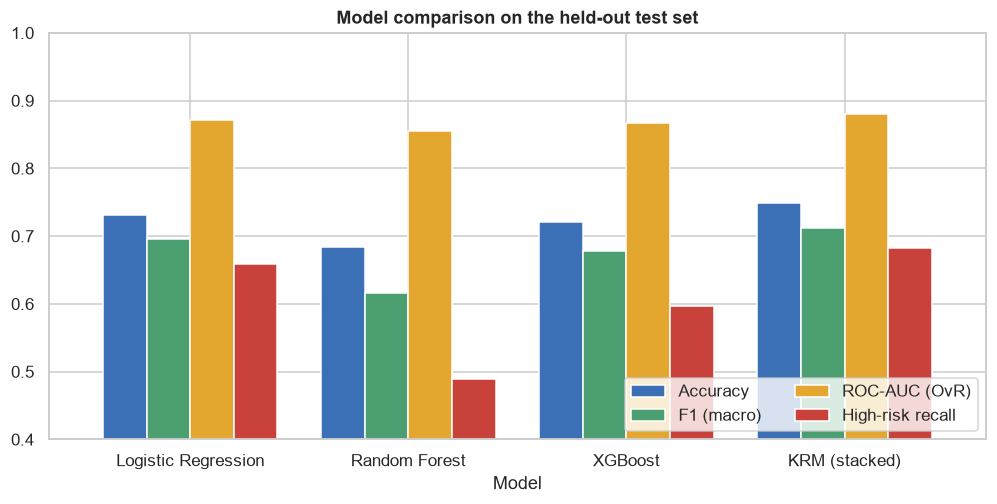

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.8))
results[["Accuracy", "F1 (macro)", "ROC-AUC (OvR)", "High-risk recall"]].plot.bar(ax=ax, width=0.8,
        color=["#3B6FB6", "#4C9F70", "#E3A72F", "#C8423B"])
ax.set_ylim(0.4, 1.0); ax.set_title("Model comparison on the held-out test set"); ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right", ncol=2); plt.show()

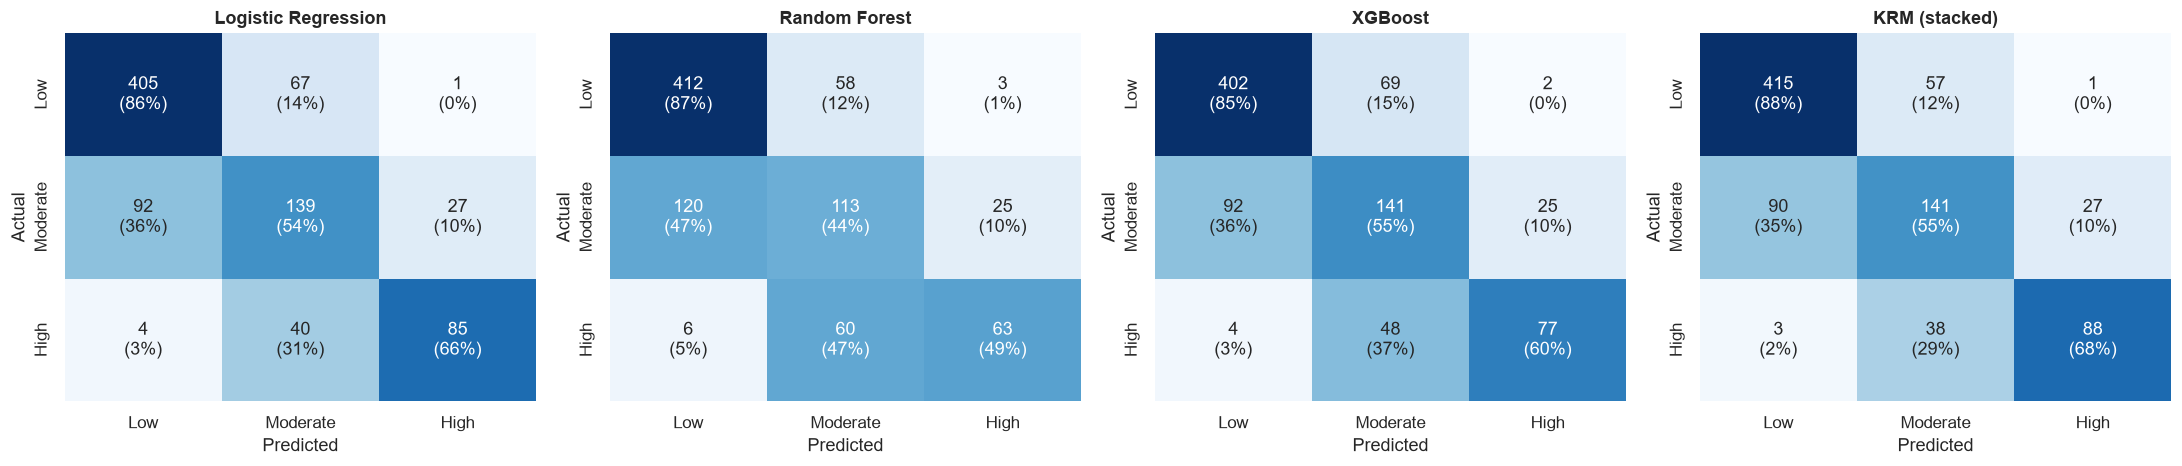

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, (name, yhat) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, yhat); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=[[f"{cm[i,j]}\n({cmn[i,j]:.0%})" for j in range(3)] for i in range(3)],
                fmt="", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

KRM classification report (test set)

              precision    recall  f1-score   support

         Low      0.817     0.877     0.846       473
    Moderate      0.597     0.547     0.571       258
        High      0.759     0.682     0.718       129

    accuracy                          0.749       860
   macro avg      0.724     0.702     0.712       860
weighted avg      0.742     0.749     0.744       860



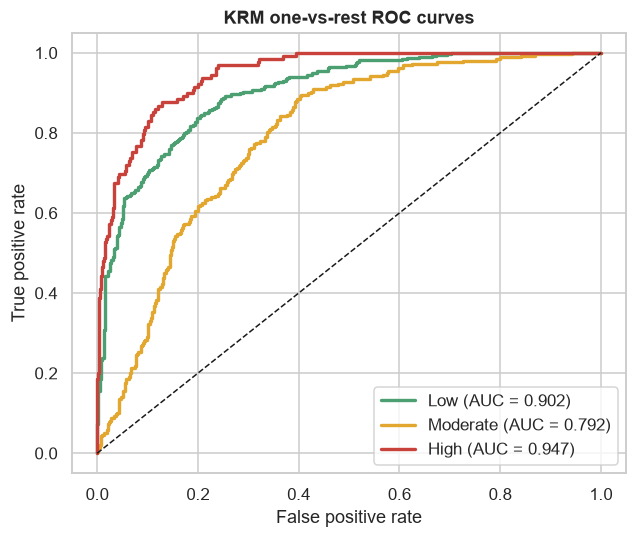

In [20]:
print("KRM classification report (test set)\n")
print(classification_report(y_test, preds["KRM (stacked)"], target_names=CLASS_NAMES, digits=3))

fig, ax = plt.subplots(figsize=(6.5, 5.2))
Yb = label_binarize(y_test, classes=[0, 1, 2])
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(Yb[:, i], probas["KRM (stacked)"][:, i])
    ax.plot(fpr, tpr, color=PALETTE[c], lw=2.2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("KRM one-vs-rest ROC curves"); ax.legend(loc="lower right"); plt.show()

In [21]:
# Stability check: KRM-vs-base-model gap on 5 repeated stratified splits of the TRAIN set
from sklearn.model_selection import cross_validate
cvr = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
stab = {}
for name, m in {"Logistic Regression": tuned["Logistic Regression"], "KRM (stacked)": krm}.items():
    s = cross_validate(clone(m), X_train.values, y_train.values, cv=cvr, scoring=["f1_macro", "accuracy"], n_jobs=1)
    stab[name] = {"F1 macro (mean)": s["test_f1_macro"].mean(), "F1 macro (std)": s["test_f1_macro"].std(),
                  "Accuracy (mean)": s["test_accuracy"].mean()}
pd.DataFrame(stab).T.round(4)

,F1 macro (mean),F1 macro (std),Accuracy (mean)
Logistic Regression,0.6973,0.0132,0.7363
KRM (stacked),0.7018,0.0121,0.7398


**Insights from the evaluation**

- **KRM is the best model on every headline metric** in this run: accuracy 0.749, macro-F1 0.712, ROC-AUC 0.880 and High-risk recall 0.682, ahead of Logistic Regression (0.731 / 0.695 / 0.872 / 0.659), XGBoost and Random Forest.
- **The margin over Logistic Regression is small** (about 2 points of accuracy and 1.7 of macro-F1). In the repeated cross-validation above the gap is about 0.005 macro-F1, which is smaller than the fold-to-fold spread of about 0.012, so the honest reading is "KRM is at least as good, and slightly better", not "KRM is decisively better". Logistic Regression does well partly because the risk pattern in this dataset is mostly additive.
- **Random Forest is the weakest**, especially on High-risk recall (0.49), so it contributes least to the ensemble.
- **The Moderate class is the hardest** (F1 about 0.57): it sits between the other two and is confused with both. Low and High are separated much better (F1 0.85 and 0.72). A Moderate prediction should therefore be read as "borderline, review the contributing factors" rather than as a sharp category.
- ROC-AUC of 0.88 shows the predicted probabilities rank respondents well even where the hard class label is wrong.

## 9. Explainability with SHAP

SHAP explains the **XGBoost** base learner with `TreeExplainer`, the tree model inside KRM that SHAP supports natively. This is a standard way to explain a stacked model whose meta-learner is a simple linear combiner. A positive SHAP value means the feature pushed the prediction *toward* the class being explained.

SHAP array: (860, 30, 3)


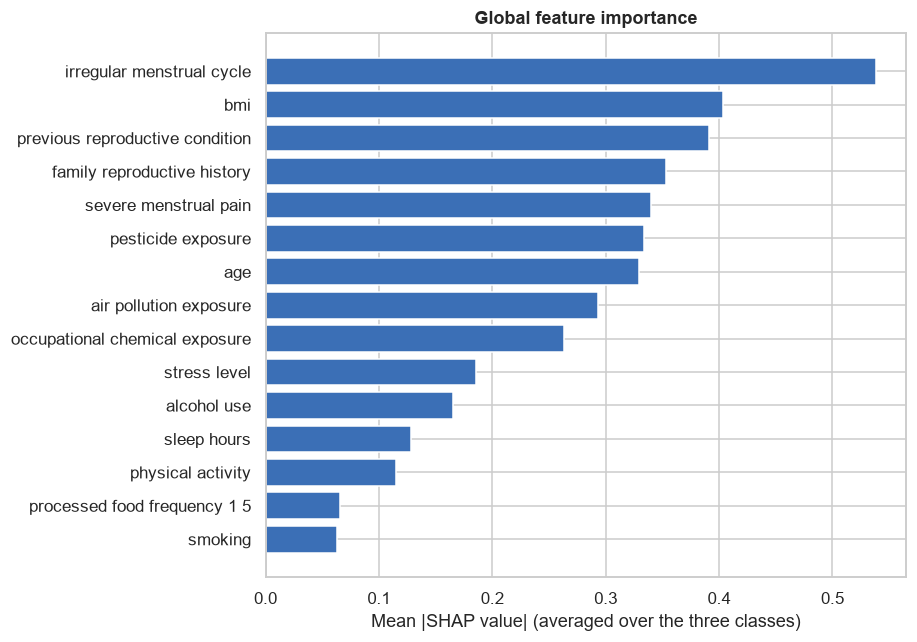

irregular_menstrual_cycle          0.538
bmi                                0.404
previous_reproductive_condition    0.391
family_reproductive_history        0.353
severe_menstrual_pain              0.340
pesticide_exposure                 0.334
age                                0.330
air_pollution_exposure             0.293
occupational_chemical_exposure     0.264
stress_level                       0.185
dtype: float32

In [22]:
xgb_model = tuned["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)
Xt = pd.DataFrame(X_test.values, columns=FEATURE_COLS)
sv = explainer(Xt)                       # shape: (n, features, classes)
print("SHAP array:", sv.values.shape)

global_imp = pd.Series(np.abs(sv.values).mean(axis=(0, 2)), index=FEATURE_COLS).sort_values(ascending=False)
top = global_imp.head(15)[::-1]
plt.figure(figsize=(8.5, 6)); plt.barh([t.replace("_", " ") for t in top.index], top.values, color="#3B6FB6")
plt.xlabel("Mean |SHAP value| (averaged over the three classes)"); plt.title("Global feature importance"); plt.tight_layout(); plt.show()
global_imp.head(10).round(3)

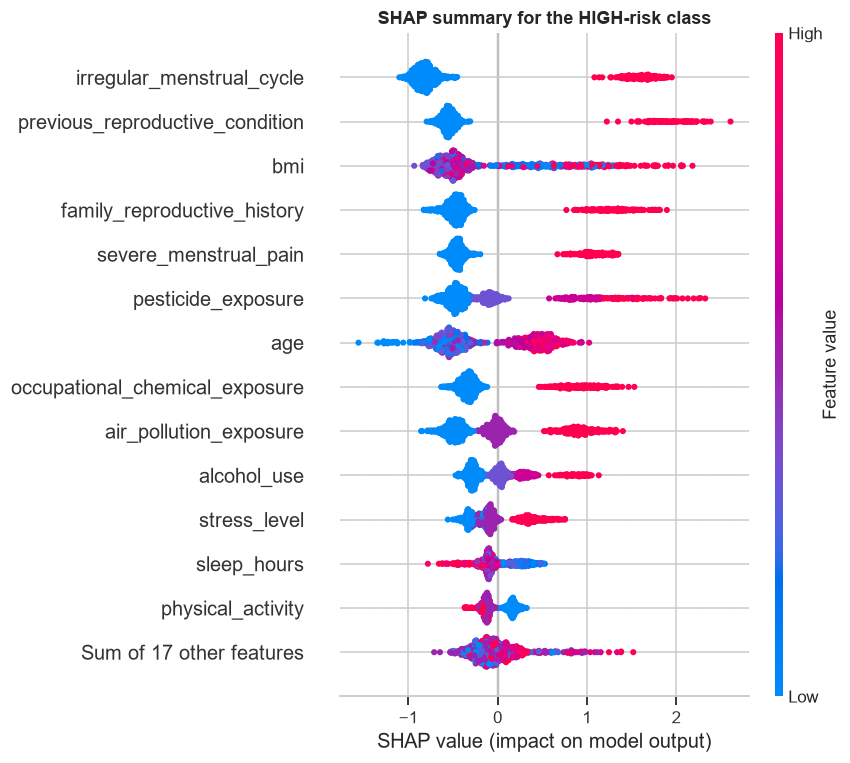

In [23]:
# Which direction does each top feature push HIGH risk?
hi = shap.Explanation(values=sv.values[:, :, 2], base_values=sv.base_values[:, 2], data=Xt.values, feature_names=FEATURE_COLS)
plt.figure(); shap.plots.beeswarm(hi, max_display=14, show=False)
plt.title("SHAP summary for the HIGH-risk class", fontsize=12, fontweight="bold"); plt.tight_layout(); plt.show()

In [24]:
rank = list(global_imp.index)
print("legume_frequency_1_5 rank:", rank.index("legume_frequency_1_5") + 1, "of", len(rank),
      "| mean |SHAP| =", round(global_imp["legume_frequency_1_5"], 4))
print("Top-5 share of total importance: %.0f%%" % (global_imp.head(5).sum()/global_imp.sum()*100))

legume_frequency_1_5 rank: 17 of 30 | mean |SHAP| = 0.0413
Top-5 share of total importance: 48%


**Insights from SHAP**

- The ranking recovers the structure seen in the EDA: **irregular menstrual cycle, BMI, previous reproductive condition, family history and severe menstrual pain** are the top drivers, followed by pesticide exposure, age, air pollution and occupational chemical exposure. Clinical-history questions come first, with the environmental block next.
- **BMI is the second most important feature**, which supports having both the numeric BMI and the BMI-category dummies in the model.
- **Dietary variables matter little here.** `legume_frequency_1_5` ranks 17th of 30 with a mean |SHAP| of about 0.04, consistent with it having no relationship to risk in the data. Fruit/vegetable and processed-food scores are also low-ranked, so claims about diet in the thesis should be worded carefully for this dataset.
- In the High-risk beeswarm, high values of the history flags, BMI, pesticide exposure and age push predictions toward High; low values pull away from it.

## 10. Saving the model

In [35]:
OUT = Path("model"); OUT.mkdir(exist_ok=True)

joblib.dump(krm, OUT / "krm_model.joblib")
for key, nm in [("Logistic Regression", "logistic_regression"), ("Random Forest", "random_forest"), ("XGBoost", "xgboost")]:
    joblib.dump(tuned[key], OUT / f"{nm}.joblib")
joblib.dump(FEATURE_COLS, OUT / "feature_columns.joblib")

# The web app expects a scaler artifact. Scaling is already inside the model pipelines,
# so this scaler is saved for compatibility/reference only.
scaler = StandardScaler().fit(X_train[NUMERIC_TO_SCALE]); joblib.dump(scaler, OUT / "scaler.joblib")

with open(OUT / "encoding_maps.json", "w") as f:
    json.dump({"ordinal_maps": ORDINAL_MAPS, "binary_maps": BINARY_MAPS, "provinces": PROVINCES,
               "numeric_cols_to_scale": NUMERIC_TO_SCALE}, f, indent=2)

manifest = {"trained_on_records": int(len(df)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
            "random_seed": SEED, "python": platform.python_version(), "scikit_learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "shap": shap.__version__,
            "test_metrics_krm": results.loc["KRM (stacked)"].to_dict()}
with open(OUT / "model_manifest.json", "w") as f: json.dump(manifest, f, indent=2)

for p in sorted(OUT.iterdir()): print(f"{p.name:28s}{p.stat().st_size/1024:9.1f} KB")

encoding_maps.json                1.5 KB
feature_columns.joblib            0.7 KB
krm_model.joblib              16152.7 KB
logistic_regression.joblib        2.9 KB
model_manifest.json               0.4 KB
random_forest.joblib          14777.6 KB
scaler.joblib                     1.1 KB
xgboost.joblib                 1364.5 KB


> **Version warning for deployment.** `joblib` files are only guaranteed to load under the *same* scikit-learn and XGBoost versions that created them. `model_manifest.json` records those versions. Pin them in `requirements.txt` (or retrain in the deployment environment) to avoid the "input stream corrupted" / `InconsistentVersionWarning` errors seen earlier.

## 11. Live tests from the saved model

Everything below reloads the model **from disk**, exactly as the web application does, so these tests exercise the saved artifacts rather than the in-memory objects.

In [26]:
krm_loaded = joblib.load(OUT / "krm_model.joblib")
xgb_loaded = joblib.load(OUT / "xgboost.joblib")
cols_loaded = joblib.load(OUT / "feature_columns.joblib")
maps = json.load(open(OUT / "encoding_maps.json"))
explainer_loaded = shap.TreeExplainer(xgb_loaded)

# Sanity check: the reloaded model must reproduce the in-memory predictions exactly
same = (krm_loaded.predict(X_test.values) == krm.predict(X_test.values)).all()
print("Reloaded model reproduces in-memory predictions on all", len(X_test), "test rows:", same)

Reloaded model reproduces in-memory predictions on all 860 test rows: True


In [27]:
RECS = {
 "irregular_menstrual_cycle": "Consider discussing your cycle pattern with a healthcare provider; menstrual irregularity can be an early indicator worth medical follow-up.",
 "severe_menstrual_pain": "Persistent severe menstrual pain is worth raising with a healthcare provider, as it can be associated with several reproductive conditions.",
 "bmi_high": "Gradual, sustainable changes toward a healthier weight range (balanced diet, regular activity) may help reduce reproductive risk.",
 "bmi_low": "Being underweight can also affect reproductive health; a nutrition-focused check-in with a healthcare provider may help.",
 "pesticide_exposure": "Where possible, reduce direct contact with pesticides (protective equipment, handwashing after exposure).",
 "air_pollution_exposure": "Reducing prolonged exposure to smoke/polluted air where practical may help lower environmental risk.",
 "occupational_chemical_exposure": "Where possible, discuss protective measures for on-the-job chemical exposure with your employer or a health provider.",
 "smoking": "Reducing or stopping smoking is one of the most impactful changes available for reproductive and general health.",
 "physical_activity": "Increasing regular moderate physical activity is associated with better reproductive/metabolic health.",
 "sleep_hours": "Aiming for more consistent, adequate sleep may support hormonal and reproductive health.",
 "stress_level": "Stress-reduction practices (rest, social support, counselling if needed) may help.",
 "fruit_veg": "Increasing fruit and vegetable intake can improve overall dietary quality linked to reproductive health.",
 "processed": "Reducing frequency of processed food may improve overall dietary quality.",
}
DISCLAIMER = ("Automated risk ESTIMATE for decision support only. Not a medical diagnosis and does not replace "
              "advice from a qualified healthcare provider.")

def recommendations(r):
    out = []
    if r["irregular_menstrual_cycle"] == "Yes": out.append(RECS["irregular_menstrual_cycle"])
    if r["severe_menstrual_pain"] == "Yes": out.append(RECS["severe_menstrual_pain"])
    if r["bmi"] >= 30: out.append(RECS["bmi_high"])
    elif r["bmi"] < 18.5: out.append(RECS["bmi_low"])
    if r["pesticide_exposure"] in ("Moderate", "High"): out.append(RECS["pesticide_exposure"])
    if r["air_pollution_exposure"] == "High": out.append(RECS["air_pollution_exposure"])
    if r["occupational_chemical_exposure"] == "Yes": out.append(RECS["occupational_chemical_exposure"])
    if r["smoking"] == "Yes": out.append(RECS["smoking"])
    if r["physical_activity"] == "Low": out.append(RECS["physical_activity"])
    if r["sleep_hours"] < 6: out.append(RECS["sleep_hours"])
    if r["stress_level"] == "High": out.append(RECS["stress_level"])
    if r["fruit_vegetable_frequency_1_5"] <= 2: out.append(RECS["fruit_veg"])
    if r["processed_food_frequency_1_5"] >= 4: out.append(RECS["processed"])
    return out[:4]

def predict_respondent(show=True, **r):
    row = engineer(pd.DataFrame([r]))[cols_loaded]
    proba = krm_loaded.predict_proba(row.values)[0]; k = int(proba.argmax())
    contrib = explainer_loaded(row)[0, :, k].values
    order = np.argsort(-np.abs(contrib))[:5]
    factors = [(cols_loaded[i].replace("_", " "), float(contrib[i])) for i in order]
    res = {"class": CLASS_NAMES[k], "proba": dict(zip(CLASS_NAMES, proba.round(3))), "factors": factors,
           "recs": recommendations(r)}
    if show:
        print(f"KRM prediction: {CLASS_NAMES[k].upper()} risk  |  " + "  ".join(f"{c} {p:.1%}" for c, p in zip(CLASS_NAMES, proba)))
        fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
        axes[0].barh(CLASS_NAMES, proba, color=[PALETTE[c] for c in CLASS_NAMES]); axes[0].set_xlim(0, 1.2)
        for i, v in enumerate(proba): axes[0].text(v + 0.01, i, f"{v:.1%}", va="center")
        axes[0].set_title(f"KRM prediction: {CLASS_NAMES[k].upper()} risk", color=PALETTE[CLASS_NAMES[k]])
        names = [f[0] for f in factors][::-1]; vals = [f[1] for f in factors][::-1]
        axes[1].barh(names, vals, color=["#4C9F70" if v < 0 else "#C8423B" for v in vals])
        axes[1].axvline(0, color="k", lw=0.8)
        axes[1].set_title(f"Top SHAP factors (red = pushes toward {CLASS_NAMES[k]}, green = pulls away)")
        plt.tight_layout(); plt.show()
        print("Suggestions:" if res["recs"] else "No elevated risk factors identified; keep up routine healthy habits.")
        for s in res["recs"]: print("  -", s)
        print("\n" + DISCLAIMER)
    return res

### Live test 1: a high-risk profile

KRM prediction: HIGH risk  |  Low 0.2%  Moderate 8.1%  High 91.7%


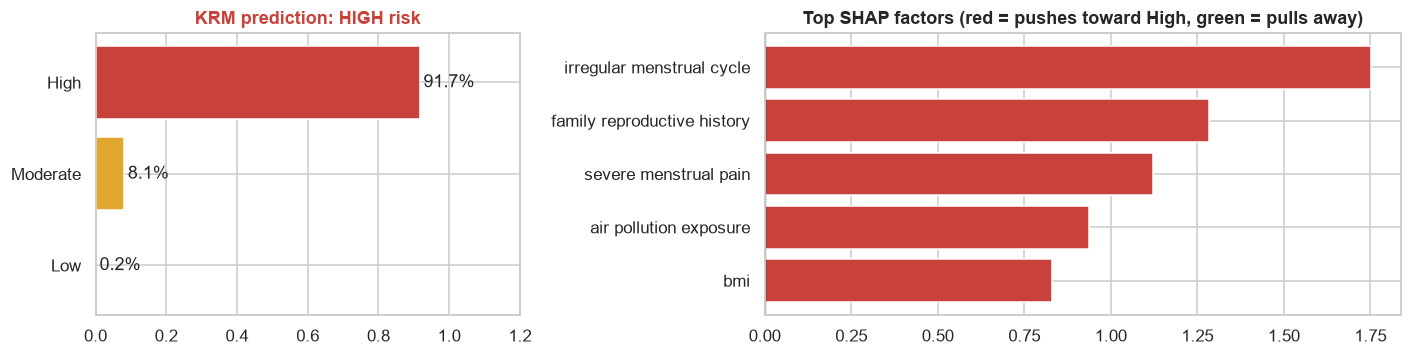

Suggestions:
  - Consider discussing your cycle pattern with a healthcare provider; menstrual irregularity can be an early indicator worth medical follow-up.
  - Persistent severe menstrual pain is worth raising with a healthcare provider, as it can be associated with several reproductive conditions.
  - Gradual, sustainable changes toward a healthier weight range (balanced diet, regular activity) may help reduce reproductive risk.
  - Reducing prolonged exposure to smoke/polluted air where practical may help lower environmental risk.

Automated risk ESTIMATE for decision support only. Not a medical diagnosis and does not replace advice from a qualified healthcare provider.


In [28]:
high_profile = dict(age=31, province="Harare", residence="Urban", bmi=31.2,
    processed_food_frequency_1_5=4, fruit_vegetable_frequency_1_5=2, legume_frequency_1_5=3,
    alcohol_use="Occasional", physical_activity="Low", sleep_hours=5.4, stress_level="High", smoking="No",
    pesticide_exposure="None", air_pollution_exposure="High", occupational_chemical_exposure="No",
    irregular_menstrual_cycle="Yes", severe_menstrual_pain="Yes",
    family_reproductive_history="Yes", previous_reproductive_condition="No")
_ = predict_respondent(**high_profile)

### Live test 2: a low-risk profile

KRM prediction: LOW risk  |  Low 93.9%  Moderate 6.0%  High 0.1%


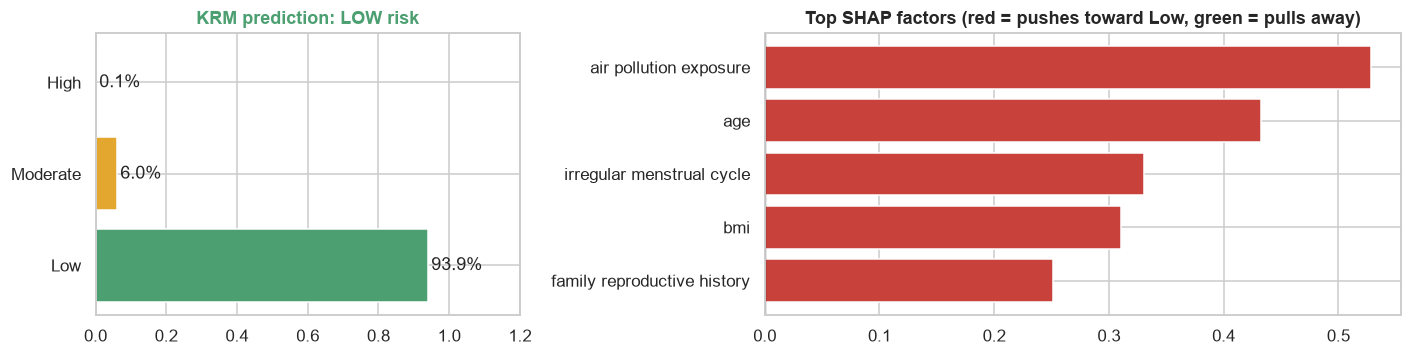

No elevated risk factors identified; keep up routine healthy habits.

Automated risk ESTIMATE for decision support only. Not a medical diagnosis and does not replace advice from a qualified healthcare provider.


In [29]:
low_profile = dict(age=26, province="Bulawayo", residence="Urban", bmi=22.0,
    processed_food_frequency_1_5=2, fruit_vegetable_frequency_1_5=5, legume_frequency_1_5=4,
    alcohol_use="None", physical_activity="High", sleep_hours=8.0, stress_level="Low", smoking="No",
    pesticide_exposure="None", air_pollution_exposure="Low", occupational_chemical_exposure="No",
    irregular_menstrual_cycle="No", severe_menstrual_pain="No",
    family_reproductive_history="No", previous_reproductive_condition="No")
_ = predict_respondent(**low_profile)

### Live test 3: a borderline (Moderate) profile, rural with pesticide exposure

KRM prediction: MODERATE risk  |  Low 5.9%  Moderate 55.5%  High 38.6%


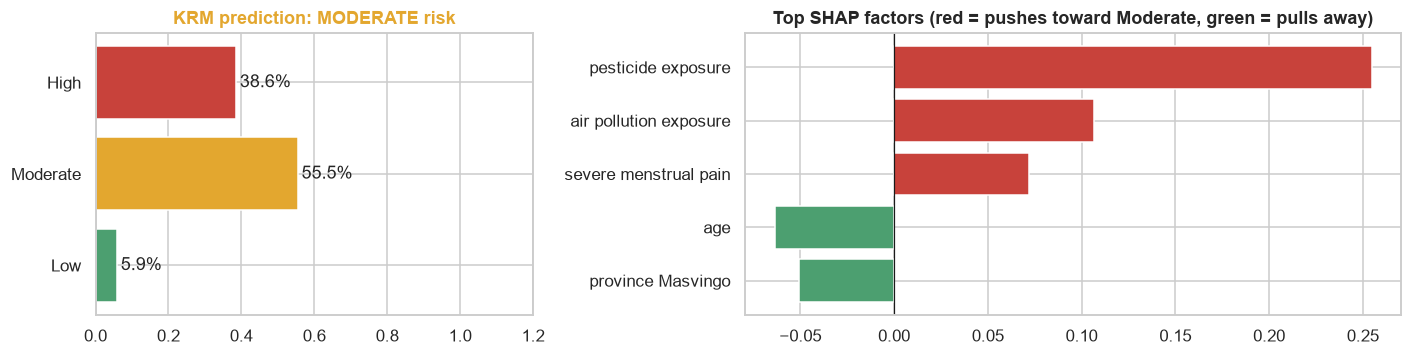

Suggestions:
  - Persistent severe menstrual pain is worth raising with a healthcare provider, as it can be associated with several reproductive conditions.
  - Where possible, reduce direct contact with pesticides (protective equipment, handwashing after exposure).
  - Where possible, discuss protective measures for on-the-job chemical exposure with your employer or a health provider.

Automated risk ESTIMATE for decision support only. Not a medical diagnosis and does not replace advice from a qualified healthcare provider.


In [30]:
mod_profile = dict(age=37, province="Masvingo", residence="Rural", bmi=27.0,
    processed_food_frequency_1_5=3, fruit_vegetable_frequency_1_5=3, legume_frequency_1_5=3,
    alcohol_use="Occasional", physical_activity="Moderate", sleep_hours=6.5, stress_level="Moderate", smoking="No",
    pesticide_exposure="Moderate", air_pollution_exposure="Moderate", occupational_chemical_exposure="Yes",
    irregular_menstrual_cycle="No", severe_menstrual_pain="Yes",
    family_reproductive_history="No", previous_reproductive_condition="No")
_ = predict_respondent(**mod_profile)

### Live test 4: what-if analysis, switching one risk factor at a time on the high-risk profile

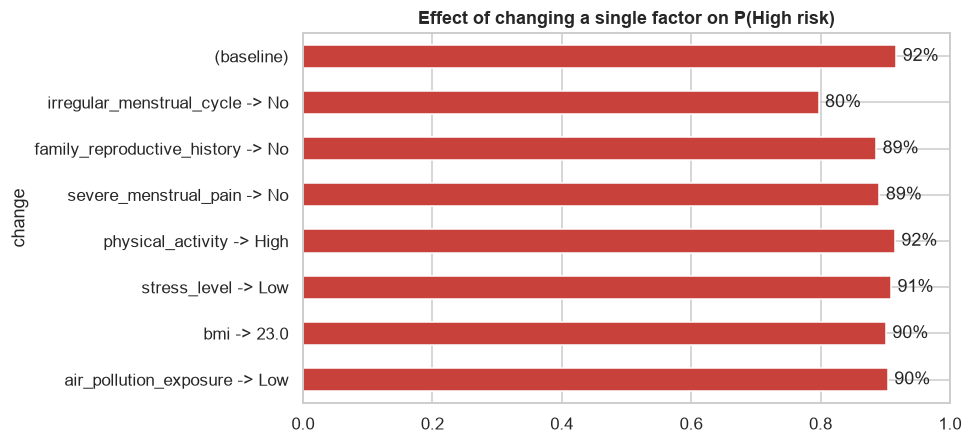

,change,predicted,P(High)
0,(baseline),High,0.917
1,irregular_menstrual_cycle -> No,High,0.797
2,family_reproductive_history -> No,High,0.886
3,severe_menstrual_pain -> No,High,0.891
4,physical_activity -> High,High,0.915
5,stress_level -> Low,High,0.909
6,bmi -> 23.0,High,0.901
7,air_pollution_exposure -> Low,High,0.904


In [31]:
base = predict_respondent(show=False, **high_profile)
changes = {"irregular_menstrual_cycle": "No", "family_reproductive_history": "No", "severe_menstrual_pain": "No",
           "physical_activity": "High", "stress_level": "Low", "bmi": 23.0, "air_pollution_exposure": "Low"}
rows = [{"change": "(baseline)", "predicted": base["class"], "P(High)": base["proba"]["High"]}]
for k, v in changes.items():
    r = predict_respondent(show=False, **{**high_profile, k: v})
    rows.append({"change": f"{k} -> {v}", "predicted": r["class"], "P(High)": r["proba"]["High"]})
wi = pd.DataFrame(rows)
ax = wi.set_index("change")["P(High)"].plot.barh(figsize=(9, 4.2), color="#C8423B")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title("Effect of changing a single factor on P(High risk)")
for i, v in enumerate(wi["P(High)"]): ax.text(v + 0.01, i, f"{v:.0%}", va="center")
plt.tight_layout(); plt.show(); wi.round(3)

**Reading the what-if chart:** no single change flips this profile out of High risk. Removing the irregular cycle has the largest effect (P(High) falls from about 92% to about 80%); the other changes move it by one to three points. That matches the SHAP ranking: the model is driven mainly by the clinical-history answers, and lifestyle changes alone move the estimate only a little.

### Live test 5: spot-check against held-out rows the model never trained on

In [32]:
holdout = df.loc[X_test.index].sample(12, random_state=3)
out = []
for _, r in holdout.iterrows():
    res = predict_respondent(show=False, **r.drop(["respondent_id", "reproductive_health_risk"]).to_dict())
    out.append({"respondent_id": r.respondent_id, "actual": r.reproductive_health_risk, "predicted": res["class"],
                "confidence": max(res["proba"].values()), "match": "yes" if res["class"] == r.reproductive_health_risk else "NO"})
spot = pd.DataFrame(out); print(f"Matched {(spot.match == 'yes').sum()} of {len(spot)}"); spot

Matched 6 of 12


,respondent_id,actual,predicted,confidence,match
0,ZW4962,Moderate,Moderate,0.565,yes
1,ZW3467,Low,Low,0.881,yes
2,ZW3933,Low,Low,0.864,yes
3,ZW2557,Moderate,Low,0.706,NO
4,ZW3548,Low,Low,0.791,yes
5,ZW4178,Low,Moderate,0.612,NO
6,ZW5558,Low,Moderate,0.628,NO
7,ZW2837,Moderate,Low,0.739,NO
8,ZW5229,Low,Low,0.927,yes
9,ZW1197,Moderate,Moderate,0.635,yes


**Reading this table:** 6 of 12 matched, lower than the 75% test accuracy. With only 12 rows that is within sampling noise, and every miss is between **adjacent** classes (Moderate vs Low, or High vs Moderate), never Low vs High. That is the Moderate-class weakness seen in the confusion matrices.

### Live test 6: edge cases and input checks

In [33]:
edge = {
 "youngest, lightest, no factors": {**low_profile, "age": 18, "bmi": 15.5},
 "oldest, obese, every history flag": {**high_profile, "age": 45, "bmi": 42.0, "previous_reproductive_condition": "Yes"},
 "sleep extremes (3h)": {**low_profile, "sleep_hours": 3.0},
}
for name, prof in edge.items():
    r = predict_respondent(show=False, **prof)
    print(f"{name:38s} -> {r['class']:9s}  P = {r['proba']}")

# Input check: the web form only offers categories the model was trained on. A typo should fail loudly, not silently.
try:
    predict_respondent(show=False, **{**low_profile, "physical_activity": "Medium"})
except Exception as e:
    print("\nInvalid category correctly rejected ->", type(e).__name__)

youngest, lightest, no factors         -> Low        P = {'Low': np.float64(0.917), 'Moderate': np.float64(0.082), 'High': np.float64(0.001)}
oldest, obese, every history flag      -> High       P = {'Low': np.float64(0.001), 'Moderate': np.float64(0.071), 'High': np.float64(0.928)}
sleep extremes (3h)                    -> Low        P = {'Low': np.float64(0.931), 'Moderate': np.float64(0.068), 'High': np.float64(0.001)}

Invalid category correctly rejected -> ValueError


### USER INPUT HERE
Edit any value in the cell below and run it.

KRM prediction: LOW risk  |  Low 93.2%  Moderate 6.7%  High 0.1%


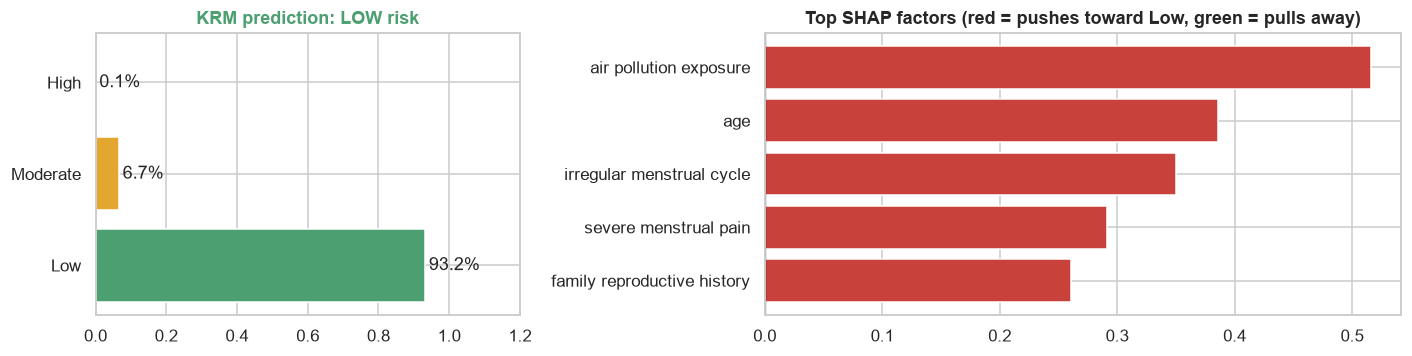

No elevated risk factors identified; keep up routine healthy habits.

Automated risk ESTIMATE for decision support only. Not a medical diagnosis and does not replace advice from a qualified healthcare provider.


In [34]:
my_profile = dict(
    age=29, province="Midlands", residence="Rural", bmi=24.5,
    processed_food_frequency_1_5=3, fruit_vegetable_frequency_1_5=3, legume_frequency_1_5=3,
    alcohol_use="None",                    # None | Occasional | Regular | Heavy
    physical_activity="Moderate",          # Low | Moderate | High
    sleep_hours=7.0,
    stress_level="Moderate",               # Low | Moderate | High
    smoking="No",                          # No | Yes
    pesticide_exposure="Low",              # None | Low | Moderate | High
    air_pollution_exposure="Low",          # Low | Moderate | High
    occupational_chemical_exposure="No",
    irregular_menstrual_cycle="No", severe_menstrual_pain="No",
    family_reproductive_history="No", previous_reproductive_condition="No")
_ = predict_respondent(**my_profile)

## THANK YOU!!!, GO TO THE KRM WEB APP